<a href="https://colab.research.google.com/github/tristanwalmsley/CO3519_Artificial-Intelligence_Lab6_Facial-Emotion-Recognition/blob/main/AI_Lab6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless

Found existing installation: opencv-contrib-python 5.0.0.93
Uninstalling opencv-contrib-python-5.0.0.93:
  Successfully uninstalled opencv-contrib-python-5.0.0.93


In [ ]:
!pip install opencv-contrib-python

  Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl (82.1 MB)


In [ ]:
import cv2
import numpy as np
import os
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
from skimage.feature import local_binary_pattern

from google.colab import drive
drive.mount('/content/drive')

# Load Haar Cascade for face detection
face_cascade = cv2.CascadeClassifier("/content/drive/My Drive/haarcascade_frontalface_default.xml")

# Function to load images, detect faces, and prepare them for feature extraction
def load_and_detect_faces(folder_path):
    images = []
    labels = []
    for label in os.listdir(folder_path):
        label_path = os.path.join(folder_path, label)
        if os.path.isdir(label_path):
            for img_file in os.listdir(label_path):
                img_path = os.path.join(label_path, img_file)
                img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
                if img is not None:
                    # Detect face
                    faces = face_cascade.detectMultiScale(img, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
                    for (x, y, w, h) in faces:
                        face_region = img[y:y+h, x:x+w]  # Crop to face region
                        images.append(face_region)
                        labels.append(label)
    return images, labels

# Set paths for training and testing folders
train_folder_path = "/content/drive/My Drive/CK_dataset/train"
test_folder_path = "/content/drive/My Drive/CK_dataset/test"

# Load and detect faces in training and testing data
X_train, y_train = load_and_detect_faces(train_folder_path)
X_test, y_test = load_and_detect_faces(test_folder_path)

radius = 1
n_points = 8 * radius

def extract_lbp_features(images):
  lbp_features = []

  for img in images:
    img = cv2.resize(img, (64, 64))
    lbp = local_binary_pattern(img, n_points, radius, method="uniform")

    (hist, _) = np.histogram(lbp.ravel(), bins=np.arange(0, n_points + 3), range=(0, n_points + 2))

    hist = hist.astype("float")
    hist /= (hist.sum() + 1e-6)
    lbp_features.append(hist)

  return np.array(lbp_features)

train_folder_path = "/content/drive/My Drive/CK_dataset/train"
test_folder_path = "/content/drive/My Drive/CK_dataset/test"

X_train_faces, y_train = load_and_detect_faces(train_folder_path)
X_train_features = extract_lbp_features(X_train_faces)

X_test_faces, y_test = load_and_detect_faces(test_folder_path)
X_test_features = extract_lbp_features(X_test_faces)

tree_classifier = DecisionTreeClassifier(max_depth=10, random_state=42)

tree_classifier.fit(X_train_features, y_train)

y_pred = tree_classifier.predict(X_test_features)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")

conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Accuracy: 24.49%
Confusion Matrix:
[[ 1  2  2  3  2  4]
 [ 1  0  1  2  0  3]
 [ 2  4  3  6  3  3]
 [ 3  2  3  8  2  6]
 [ 1  0  0  1  2  4]
 [ 2  2  3  5  2 10]]


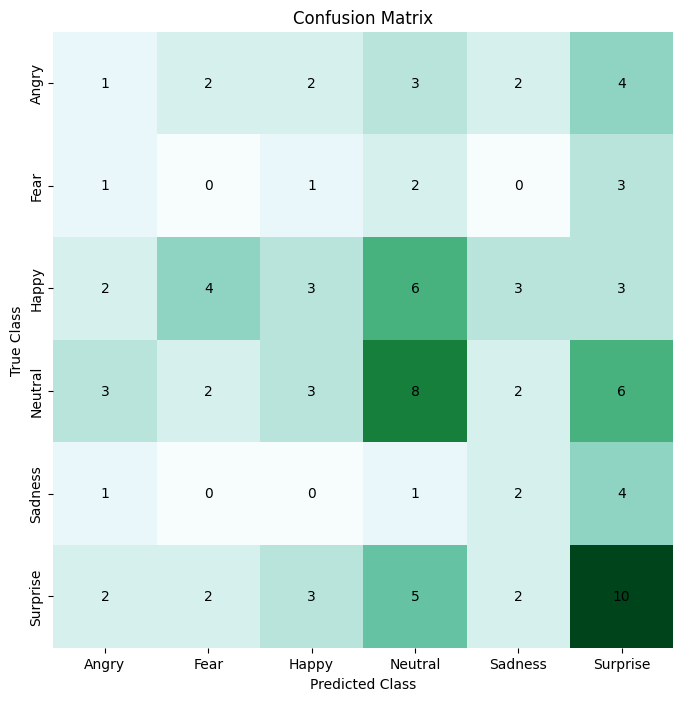

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score

class_names = ["Angry", "Fear", "Happy", "Neutral", "Sadness", "Surprise"]

conf_matrix = confusion_matrix(y_test, y_pred)

conf_matrix_percent = conf_matrix / conf_matrix.sum(axis=1, keepdims=True) * 100

plt.figure(figsize=(8, 8))
ax = sns.heatmap(conf_matrix, annot=False, cmap="BuGn", xticklabels=class_names, yticklabels=class_names, cbar=False)

for i in range(conf_matrix.shape[0]):
  for j in range(conf_matrix.shape[1]):
    count = conf_matrix[i, j]
    ax.text(j + 0.5, i + 0.5, f"{count}", ha="center", va="center", color="black", fontsize=10)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix")
plt.show()

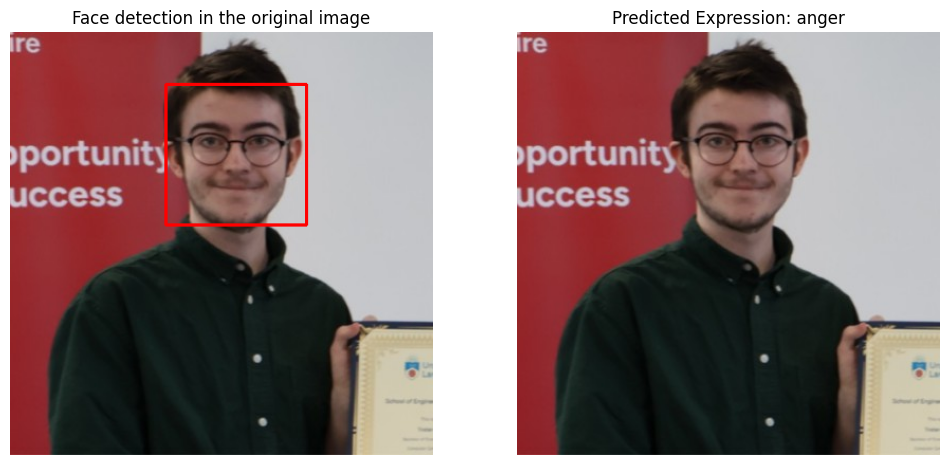

In [ ]:
def predict_emotion(image_path, model):
  img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
  if img is None:
    raise ValueError("Image not found or could not be loaded.")

  faces = face_cascade.detectMultiScale(img, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
  if len(faces) == 0:
    print("No face detected.")
    return

  for (x, y, w, h) in faces:
    face_region = img[y:y+h, x:x+w]
    face_region = cv2.resize(face_region, (64, 64))
    lbp = local_binary_pattern(face_region, n_points, radius, method="uniform")

    hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, n_points + 3), range=(0, n_points + 2))
    hist = hist.astype("float")
    hist /= (hist.sum() + 1e-6)

    features = hist.reshape(1, -1)
    predicted_expression = model.predict(features)[0]

    img_rgb = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)

    img_with_box = img_rgb.copy()
    cv2.rectangle(img_with_box, (x, y), (x + w, y + h), (255, 0, 0), 2)

    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(img_with_box)
    plt.title(f"Face detection in the original image")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(img_rgb)
    plt.title(f"Predicted Expression: {predicted_expression}")
    plt.axis('off')

    plt.show()

image_path = "/content/drive/My Drive/test_images/1.jpeg"
predict_emotion(image_path, tree_classifier)